<a href="https://colab.research.google.com/github/juliaBerserk/rea-artificial-intelligence-systems-tasks/blob/main/Task4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import scipy
from io import IncrementalNewlineDecoder

In [2]:
#sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

In [3]:
#глубокое обучение
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [4]:
from matplotlib import pyplot
%matplotlib inline

In [7]:
# Загружаем необходимые данные. В датасете нет названия колонок.
# Целевой переменной является последний столбец
path='https://raw.githubusercontent.com/jbrownlee/Datasets/master/banknote_authentication.csv'
df=pd.read_csv(path, header=None)

In [6]:
df.head()

,0,1,2,3,4
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [8]:
# Проведите описательную статистику для изучения данных
# с помощью метода describe()
df.describe()

,0,1,2,3,4
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [9]:
# Проведите корреляцию признаков с помощью метода corr().
# Сделайте вывод.
df.corr()

,0,1,2,3,4
0,1.000000,0.264026,-0.380850,0.276817,-0.724843
1,0.264026,1.000000,-0.786895,-0.526321,-0.444688
2,-0.380850,-0.786895,1.000000,0.318841,0.155883
3,0.276817,-0.526321,0.318841,1.000000,-0.023424
4,-0.724843,-0.444688,0.155883,-0.023424,1.000000


In [10]:
# Проверьте с помощью метода info()
# типы данных и общую информацию.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       1372 non-null   float64
 1   1       1372 non-null   float64
 2   2       1372 non-null   float64
 3   3       1372 non-null   float64
 4   4       1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB


In [11]:
# Проверим данные в последней колонке. Сделаем вывод о балансировке данных
# и возможности создания нейронной сети:
df[4].value_counts()

,count
4,
0,762
1,610


In [15]:
# Создаем Х и у. Х приведем к типу данных float32
X, y = df.values[:, :-1], df.values[:, -1]
X=X.astype('float32')
X[1]

array([ 4.5459,  8.1674, -2.4586, -1.4621], dtype=float32)

In [16]:
# Применим LabelEncoder() для у
y=LabelEncoder().fit_transform(y)

In [17]:
# Разделим данные на обучающую и тестовую выборки.
# Параметр shuffle=True позволит перемешать выборку
X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=0.25, shuffle=True)

In [24]:
# Создадим нейронную сеть
n_features=X.shape[1] # такие данные примет нейронная сеть на 1 слое
model=Sequential() # нейронная сеть последовательная
model.add(Dense(20, activation='relu', input_shape=(n_features,)))
model.add(Dense(10, activation='relu'))

In [25]:
# выходной слой
model.add(Dense(1, activation='sigmoid')) # 1- так как классов у нас 1 (либо 0 либо 1)

In [26]:
# Компилируем модель
model.compile(optimizer='adam', loss='binary_crossentropy')

In [27]:
# Проведем обучение модели. batch_size - часть данных,
# которую мы подаем на вход, verbose - визуализация
history=model.fit(X_train, y_train,
                  epochs=20,
                  batch_size=32,
                  verbose=1,
                  validation_data=(X_test,y_test))


Epoch 1/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.7061 - val_loss: 0.5378
Epoch 2/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4626 - val_loss: 0.3768
Epoch 3/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3423 - val_loss: 0.2761
Epoch 4/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2644 - val_loss: 0.2149
Epoch 5/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2083 - val_loss: 0.1675
Epoch 6/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1638 - val_loss: 0.1327
Epoch 7/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1298 - val_loss: 0.1061
Epoch 8/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1033 - val_loss: 0.0851
Epoch 9/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0826 - val_loss: 0.0682
Epoch 10/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0662 - val_loss: 0.0559
Epoch 11/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0530 - val_loss: 0.0454
Epoch 12/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0427 - val_lo

In [28]:
# Получим прогноз для X_test
yhat = model.predict(X_test)  # X_test - ваши входные данные
predicted_classes = np.argmax(yhat, axis=-1)

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


In [29]:
# Валидируем наш прогноз
score=accuracy_score(y_test, predicted_classes)
print('Accuracy:', score)

Accuracy: 0.5860058309037901


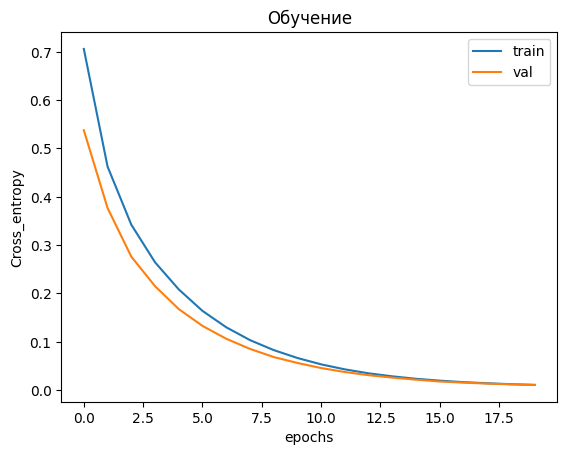

In [30]:
# Осуществим визуализацию процесса обучения
pyplot.title('Обучение')
pyplot.xlabel('еpochs')
pyplot.ylabel('Cross_entropy')
pyplot.plot(history.history['loss'], label='train')
pyplot.plot(history.history['val_loss'], label='val')
pyplot.legend()
pyplot.show()

In [31]:
# Применим кросс-валидацию для обучения созданной нейронной сети:
from sklearn.model_selection import StratifiedKFold
kfold=StratifiedKFold(10)
scores=[] #пустой список для метрик

for train_ix, test_ix in kfold.split(X,y):
  X_train, X_test, y_train, y_test = X[train_ix], X[test_ix], y[train_ix], y[test_ix]
  n_features=X.shape[1] #размерность

In [33]:
model=Sequential() # нейронная сеть последовательная
model.add(Dense(20, activation='relu', input_shape=(n_features,)))
model.add(Dense(10, activation='relu'))

In [34]:
# выходной слой
model.add(Dense(1, activation='sigmoid')) # 1- так как классов у нас 1 (либо 0 либо 1)

In [36]:
#Компилируем модель
model.compile(optimizer='adam', loss='binary_crossentropy')

In [37]:
#Обучение модели
history=model.fit(X_train, y_train,
                  epochs=20,
                  batch_size=32,
                  verbose=1,
                  validation_data=(X_test,y_test))

Epoch 1/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.7164 - val_loss: 0.6001
Epoch 2/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.5434 - val_loss: 0.4982
Epoch 3/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.4400 - val_loss: 0.3942
Epoch 4/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.3081 - val_loss: 0.2512
Epoch 5/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1883 - val_loss: 0.1606
Epoch 6/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1184 - val_loss: 0.1083
Epoch 7/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0788 - val_loss: 0.0777
Epoch 8/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0554 - val_loss: 0.0575
Epoch 9/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0412 - val_loss: 0.0461
Epoch 10/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0316 - val_loss: 0.0365
Epoch 11/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0246 - val_loss: 0.0304
Epoch 12/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0200 - va

In [38]:
#predict test_set
yhat = model.predict(X_test)  # X_test - ваши входные данные
predicted_classes = np.argmax(yhat, axis=-1)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


In [39]:
#Валидируем наш прогноз
score=accuracy_score(y_test, predicted_classes)
print('Accuracy:', score)

Accuracy: 0.5547445255474452


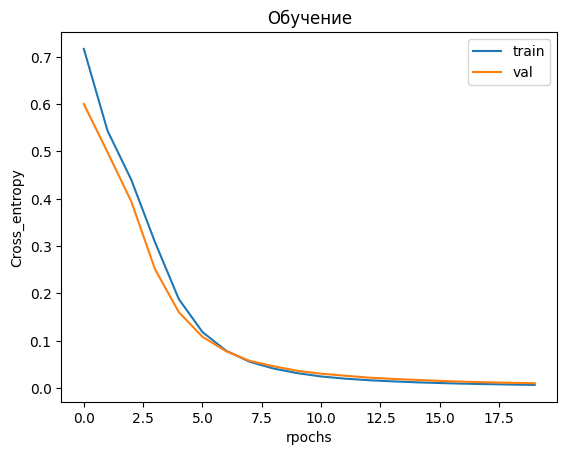

Средняя точность при кроссвалидации: 0.5547445255474452


In [43]:
#визуализация процесса обучения
pyplot.title('Обучение')
pyplot.xlabel('rpochs')
pyplot.ylabel('Cross_entropy')
pyplot.plot(history.history['loss'], label='train')
pyplot.plot(history.history['val_loss'], label='val')
pyplot.legend()
pyplot.show()

scores.append(score)
print('Средняя точность при кроссвалидации:', (np.mean(scores)))

Epoch 1/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.3989 - val_loss: 0.2766
Epoch 2/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.2287 - val_loss: 0.1572
Epoch 3/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1500 - val_loss: 0.1008
Epoch 4/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.1051 - val_loss: 0.0713
Epoch 5/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0776 - val_loss: 0.0525
Epoch 6/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0585 - val_loss: 0.0394
Epoch 7/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0447 - val_loss: 0.0310
Epoch 8/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0351 - val_loss: 0.0251
Epoch 9/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0275 - val_loss: 0.0197
Epoch 10/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0221 - val_loss: 0.0165
Epoch 11/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0179 - val_loss: 0.0139
Epoch 12/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0150 - va

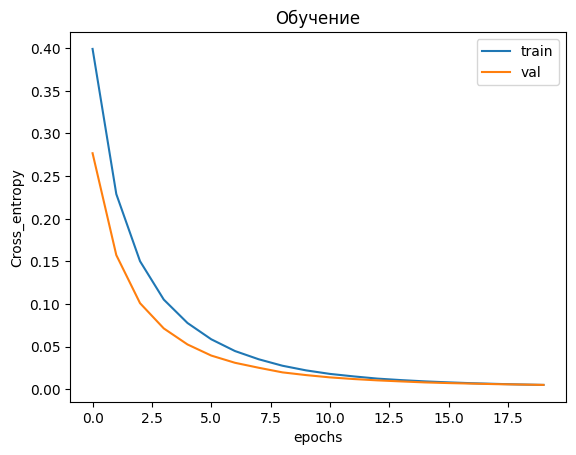

Epoch 1/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.8156 - val_loss: 0.5445
Epoch 2/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4552 - val_loss: 0.3788
Epoch 3/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3314 - val_loss: 0.2881
Epoch 4/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2621 - val_loss: 0.2266
Epoch 5/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1750 - val_loss: 0.1521
Epoch 6/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1166 - val_loss: 0.1190
Epoch 7/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0887 - val_loss: 0.0948
Epoch 8/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0657 - val_loss: 0.0751
Epoch 9/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0492 - val_loss: 0.0613
Epoch 10/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0387 - val_loss: 0.0510
Epoch 11/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0313 - val_loss: 0.0432
Epoch 12/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0257 - val_lo

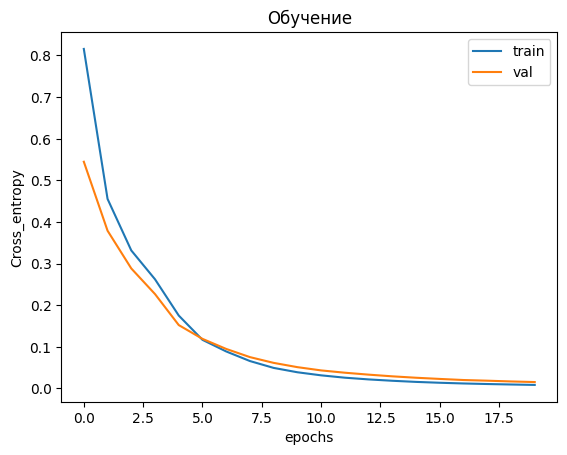

Epoch 1/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.7150 - val_loss: 0.4958
Epoch 2/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4200 - val_loss: 0.3750
Epoch 3/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3243 - val_loss: 0.2888
Epoch 4/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2424 - val_loss: 0.2070
Epoch 5/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1752 - val_loss: 0.1418
Epoch 6/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1180 - val_loss: 0.0920
Epoch 7/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0805 - val_loss: 0.0659
Epoch 8/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0592 - val_loss: 0.0506
Epoch 9/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0481 - val_loss: 0.0419
Epoch 10/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0403 - val_loss: 0.0352
Epoch 11/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0346 - val_loss: 0.0297
Epoch 12/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0296 - val_l

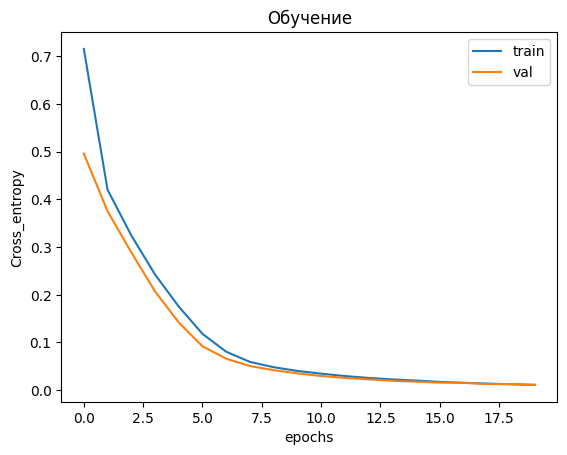

Epoch 1/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6612 - val_loss: 0.4352
Epoch 2/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3723 - val_loss: 0.3012
Epoch 3/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2687 - val_loss: 0.2155
Epoch 4/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1984 - val_loss: 0.1569
Epoch 5/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1467 - val_loss: 0.1174
Epoch 6/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1106 - val_loss: 0.0884
Epoch 7/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0859 - val_loss: 0.0686
Epoch 8/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0687 - val_loss: 0.0545
Epoch 9/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0564 - val_loss: 0.0442
Epoch 10/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0473 - val_loss: 0.0374
Epoch 11/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0402 - val_loss: 0.0310
Epoch 12/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0342 - val_lo

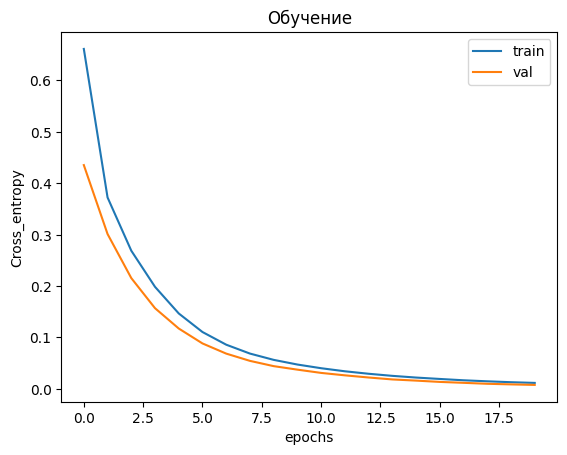

Epoch 1/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.6856 - val_loss: 0.5859
Epoch 2/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4757 - val_loss: 0.3921
Epoch 3/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3214 - val_loss: 0.2594
Epoch 4/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2129 - val_loss: 0.1699
Epoch 5/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1411 - val_loss: 0.1157
Epoch 6/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0946 - val_loss: 0.0777
Epoch 7/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0629 - val_loss: 0.0508
Epoch 8/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0425 - val_loss: 0.0364
Epoch 9/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0301 - val_loss: 0.0279
Epoch 10/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0224 - val_loss: 0.0236
Epoch 11/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0177 - val_loss: 0.0202
Epoch 12/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0146 - val_lo

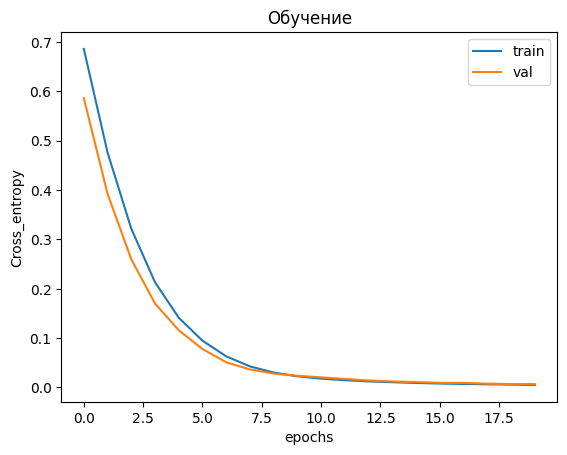

Epoch 1/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5336 - val_loss: 0.3988
Epoch 2/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3099 - val_loss: 0.2409
Epoch 3/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1968 - val_loss: 0.1495
Epoch 4/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1296 - val_loss: 0.0956
Epoch 5/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0906 - val_loss: 0.0685
Epoch 6/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0674 - val_loss: 0.0498
Epoch 7/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0516 - val_loss: 0.0378
Epoch 8/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0397 - val_loss: 0.0304
Epoch 9/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0318 - val_loss: 0.0248
Epoch 10/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0257 - val_loss: 0.0204
Epoch 11/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0208 - val_loss: 0.0170
Epoch 12/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0170 - val_lo

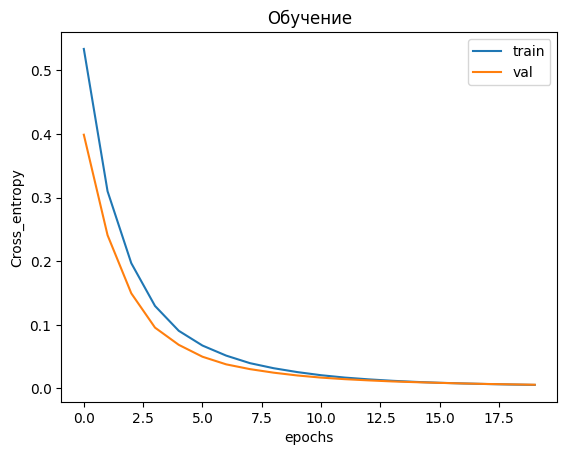

Epoch 1/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.6008 - val_loss: 0.4224
Epoch 2/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3479 - val_loss: 0.2432
Epoch 3/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2027 - val_loss: 0.1547
Epoch 4/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1303 - val_loss: 0.1082
Epoch 5/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0911 - val_loss: 0.0802
Epoch 6/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0659 - val_loss: 0.0608
Epoch 7/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0495 - val_loss: 0.0482
Epoch 8/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0384 - val_loss: 0.0391
Epoch 9/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0309 - val_loss: 0.0327
Epoch 10/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0254 - val_loss: 0.0279
Epoch 11/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0213 - val_loss: 0.0237
Epoch 12/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0180 - val_lo

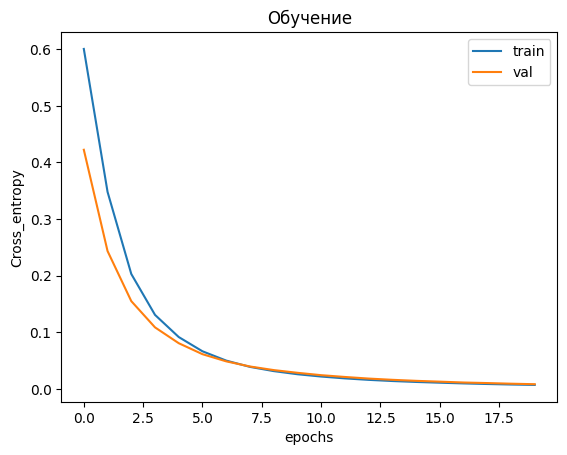

Epoch 1/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.9835 - val_loss: 0.7066
Epoch 2/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5395 - val_loss: 0.4212
Epoch 3/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3449 - val_loss: 0.2967
Epoch 4/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2465 - val_loss: 0.2202
Epoch 5/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1839 - val_loss: 0.1685
Epoch 6/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1427 - val_loss: 0.1354
Epoch 7/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1128 - val_loss: 0.1072
Epoch 8/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0916 - val_loss: 0.0889
Epoch 9/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0750 - val_loss: 0.0756
Epoch 10/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0626 - val_loss: 0.0630
Epoch 11/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0531 - val_loss: 0.0560
Epoch 12/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0453 - val_lo

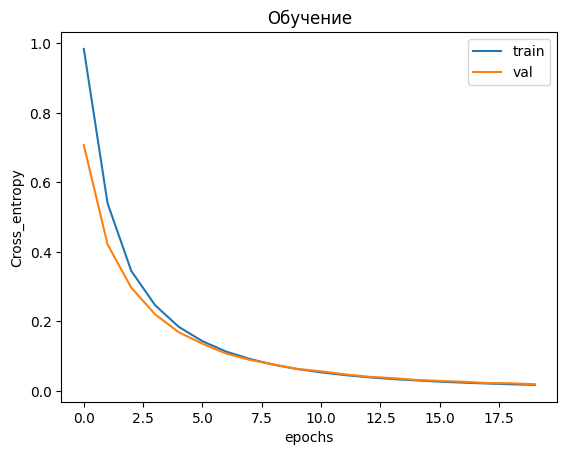

Epoch 1/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5932 - val_loss: 0.4182
Epoch 2/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3787 - val_loss: 0.2823
Epoch 3/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2413 - val_loss: 0.1881
Epoch 4/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1488 - val_loss: 0.1160
Epoch 5/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0885 - val_loss: 0.0681
Epoch 6/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0550 - val_loss: 0.0469
Epoch 7/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0375 - val_loss: 0.0334
Epoch 8/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0284 - val_loss: 0.0261
Epoch 9/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0222 - val_loss: 0.0226
Epoch 10/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0185 - val_loss: 0.0180
Epoch 11/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0154 - val_loss: 0.0155
Epoch 12/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0132 - val_lo

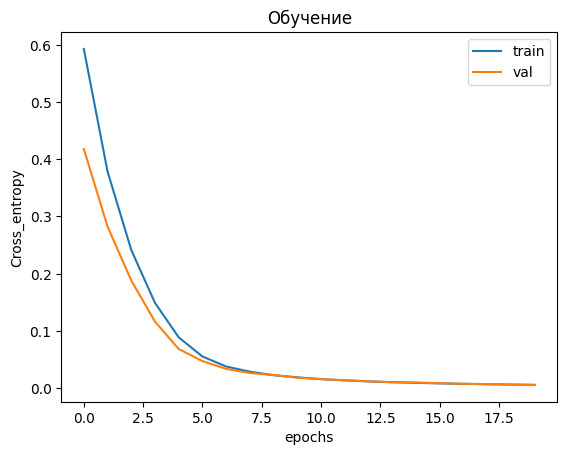

Epoch 1/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.6116 - val_loss: 0.4992
Epoch 2/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4655 - val_loss: 0.3728
Epoch 3/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3430 - val_loss: 0.2592
Epoch 4/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2322 - val_loss: 0.1580
Epoch 5/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1398 - val_loss: 0.0796
Epoch 6/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0832 - val_loss: 0.0468
Epoch 7/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0549 - val_loss: 0.0322
Epoch 8/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0404 - val_loss: 0.0218
Epoch 9/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0302 - val_loss: 0.0177
Epoch 10/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0237 - val_loss: 0.0143
Epoch 11/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0190 - val_loss: 0.0117
Epoch 12/20
39/39 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0156 - val_l

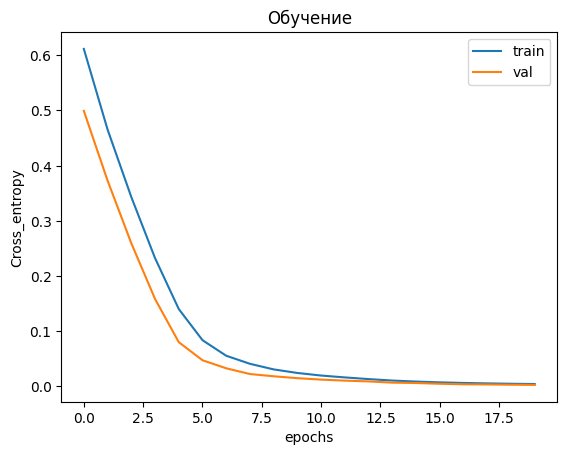

Средняя точность при кроссвалидации: 1.0


In [55]:
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
scores = []  # пустой список для метрик

for train_ix, test_ix in kfold.split(X, y):
    X_train, X_test = X[train_ix], X[test_ix]
    y_train, y_test = y[train_ix], y[test_ix]
    n_features = X.shape[1]

    # новая модель на каждом фолде
    model = Sequential()
    model.add(Input(shape=(n_features,)))
    model.add(Dense(20, activation='relu'))
    model.add(Dense(10, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))

    # компиляция
    model.compile(optimizer='adam', loss='binary_crossentropy')

    # обучение
    history = model.fit(X_train, y_train,
                        epochs=20,
                        batch_size=32,
                        verbose=1,
                        validation_data=(X_test, y_test))

    # прогноз на тестовом фолде
    yhat = model.predict(X_test)
    predicted_classes = (yhat > 0.5).astype(int).ravel()

    # валидация
    score = accuracy_score(y_test, predicted_classes)
    print('Accuracy:', score)

    # визуализация процесса обучения
    pyplot.title('Обучение')
    pyplot.xlabel('epochs')
    pyplot.ylabel('Cross_entropy')
    pyplot.plot(history.history['loss'], label='train')
    pyplot.plot(history.history['val_loss'], label='val')
    pyplot.legend()
    pyplot.show()

    scores.append(score)

print('Средняя точность при кроссвалидации:', np.mean(scores))